In [5]:
import matplotlib.pyplot as plt
import geopandas as gpd
import folium
import numpy as np
import matplotlib.dates as mdates

In [6]:
linea_base_viento = xr.open_dataset("Linea_Base_Viento_AMG.nc")
poligono_amg = gpd.read_file("amg_limites.geojson").to_crs("EPSG:4326")
cubo_viento = xr.open_dataset("Cubo_Viento_AMG_Final.nc")

In [1]:
import xarray as xr

cubo_no2 = xr.open_dataset("Cubo_NO2_Final.nc")["NO2"]
cubo_ch4 = xr.open_dataset("Cubo_CH4_Final.nc")["CH4"]

print("Cubos cargados")

Cubos cargados


In [2]:
linea_base_no2 = xr.open_dataset("Linea_Base_NO2_AMG.nc")["NO2"]
linea_base_ch4 = xr.open_dataset("Linea_Base_CH4_AMG.nc")["CH4"]
print("Línea base cargada")

Línea base cargada


In [3]:
!pip install imageio[ffmpeg]

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 68.0/68.0 MB 34.2 MB/s eta 0:00:00:00:0100:01


In [5]:
import matplotlib.pyplot as plt
import geopandas as gpd
import folium
import numpy as np
import matplotlib.dates as mdates

In [6]:
linea_base_viento = xr.open_dataset("Linea_Base_Viento_AMG.nc")
poligono_amg = gpd.read_file("amg_limites.geojson").to_crs("EPSG:4326")
cubo_viento = xr.open_dataset("Cubo_Viento_AMG_Final.nc")

In [ ]:
#### Gráfica de Hotspots

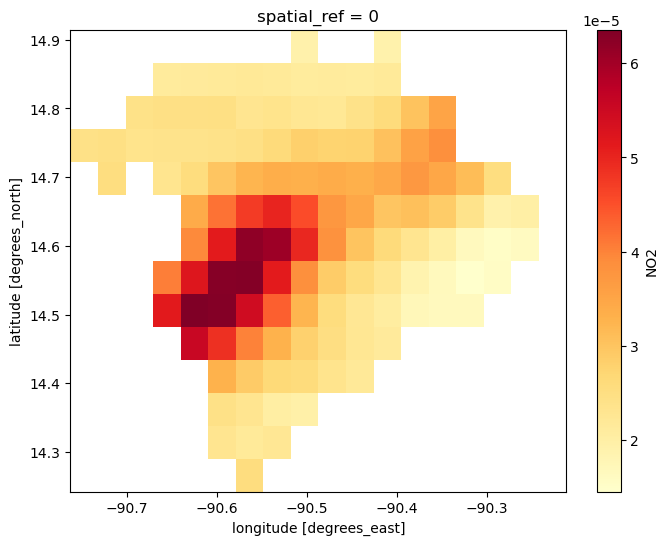

In [3]:
linea_base_no2.plot(cmap="YlOrRd", size=6)

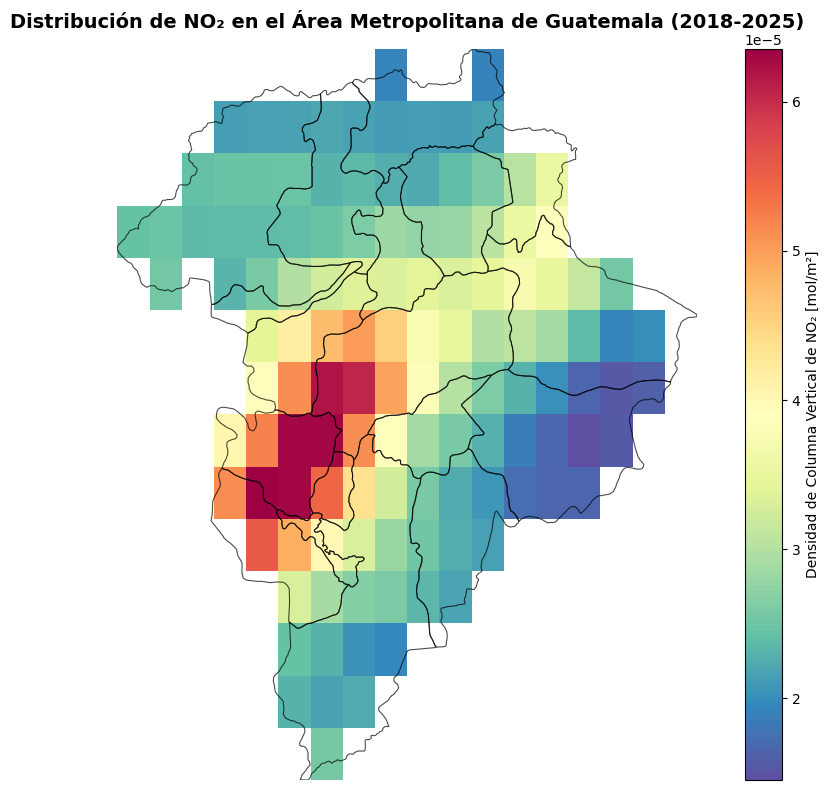

In [10]:
import matplotlib.pyplot as plt
import geopandas as gpd
poligono_amg = gpd.read_file("mystorage/amg_limites.geojson")
poligono_amg = poligono_amg.to_crs("EPSG:4326")
fig, ax = plt.subplots(figsize=(10, 8))

linea_base_no2.plot(
    ax=ax,
    cmap="Spectral_r",
    cbar_kwargs={'label': 'Densidad de Columna Vertical de NO₂ [mol/m²]'}
)

poligono_amg.plot(
    ax=ax,
    facecolor="none",       
    edgecolor="black",      
    linewidth=0.8,
    alpha=0.7
)

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")

for spine in ax.spines.values():
    spine.set_visible(False)

plt.title("Distribución de NO₂ en el Área Metropolitana de Guatemala (2018-2025)", 
          fontsize=14, fontweight="bold", pad=15)

plt.tight_layout()
plt.savefig("mapa_linea_base_no2.png", dpi=300, bbox_inches='tight')
plt.show()

In [5]:
import folium
import numpy as np
import rioxarray


lat_no2 = 14.50644994392857
lon_no2 = -90.624926285

serie_hotspot_no2 = cubo_no2.sel(x=lon_no2, y=lat_no2, method="nearest")
meses_validos = serie_hotspot_no2.dropna(dim="time")

print(f"Total de meses con lectura válida en este píxel: {len(meses_validos)} de 84 meses")
print("\nFechas exactas y valores (mol/m2) registrados en esta coordenada:")
for fecha, valor in zip(meses_validos.time.dt.strftime('%Y-%m').values, meses_validos.values):
    print(f"  • {fecha}: {valor:.3e} mol/m²")
res_x, res_y = cubo_no2.rio.resolution(recalc=True)

dx = abs(res_x) / 2
dy = abs(res_y) / 2

mapa_forense = folium.Map(location=[lat_no2, lon_no2], zoom_start=13, tiles="OpenStreetMap")

folium.TileLayer(
    tiles='https://mt1.google.com/vt/lyrs=y&x={x}&y={y}&z={z}',
    attr='Google',
    name='Google Satellite Híbrido'
).add_to(mapa_forense)

limites_pixel = [[lat_no2 - dy, lon_no2 - dx], [lat_no2 + dy, lon_no2 + dx]]
folium.Rectangle(
    bounds=limites_pixel,
    color="#900C3F",
    weight=3,
    fill=True,
    fill_color="#C70039",
    fill_opacity=0.25,
    popup="Celda de la cuadrícula de salida de NO₂"
).add_to(mapa_forense)

folium.Marker(
    location=[lat_no2, lon_no2],
    popup=(
        f"Centro de la celda seleccionada de NO₂: "
        f"{meses_validos.mean().item():.3e} mol/m²"
    ),
    
    icon=folium.Icon(color="red", icon="info-sign")
).add_to(mapa_forense)

folium.LayerControl().add_to(mapa_forense)
mapa_forense

Total de meses con lectura válida en este píxel: 73 de 84 meses

Fechas exactas y valores (mol/m2) registrados en esta coordenada:
  • 2018-07: 4.570e-05 mol/m²
  • 2018-09: 5.612e-05 mol/m²
  • 2018-11: 3.997e-05 mol/m²
  • 2018-12: 8.911e-05 mol/m²
  • 2019-01: 7.247e-05 mol/m²
  • 2019-02: 8.299e-05 mol/m²
  • 2019-03: 8.351e-05 mol/m²
  • 2019-04: 1.547e-04 mol/m²
  • 2019-05: 3.453e-05 mol/m²
  • 2019-06: 6.085e-05 mol/m²
  • 2019-07: 3.737e-05 mol/m²
  • 2019-09: 1.754e-04 mol/m²
  • 2019-10: 2.950e-05 mol/m²
  • 2019-11: 7.831e-05 mol/m²
  • 2019-12: 1.046e-04 mol/m²
  • 2020-01: 3.785e-05 mol/m²
  • 2020-02: 7.762e-05 mol/m²
  • 2020-03: 5.209e-05 mol/m²
  • 2020-04: 2.335e-05 mol/m²
  • 2020-07: 3.029e-05 mol/m²
  • 2020-08: 2.252e-05 mol/m²
  • 2020-09: 5.036e-05 mol/m²
  • 2020-11: 2.462e-05 mol/m²
  • 2020-12: 5.118e-05 mol/m²
  • 2021-01: 3.362e-05 mol/m²
  • 2021-02: 5.507e-05 mol/m²
  • 2021-03: 6.373e-05 mol/m²
  • 2021-04: 9.268e-05 mol/m²
  • 2021-07: 3.783e-05 mol/m²

In [13]:
max_no2_val = linea_base_no2.max()
hotspot_no2 = linea_base_no2.where(linea_base_no2 == max_no2_val, drop=True)
latitud_no2 = hotspot_no2.y.values[0]
longitud_no2 = hotspot_no2.x.values[0]
concentracion_max_no2 = hotspot_no2.values[0][0]
print("Hotspot Histórico de NO2 (2018-2025)")
print(f"Latitud : {latitud_no2}")
print(f"Longitud: {longitud_no2}")
print(f"Valor   : {concentracion_max_no2} mol/m²")

Hotspot Histórico de NO2 (2018-2025)
Latitud : 14.50644994392857
Longitud: -90.624926285
Valor   : 6.354493962135166e-05 mol/m²


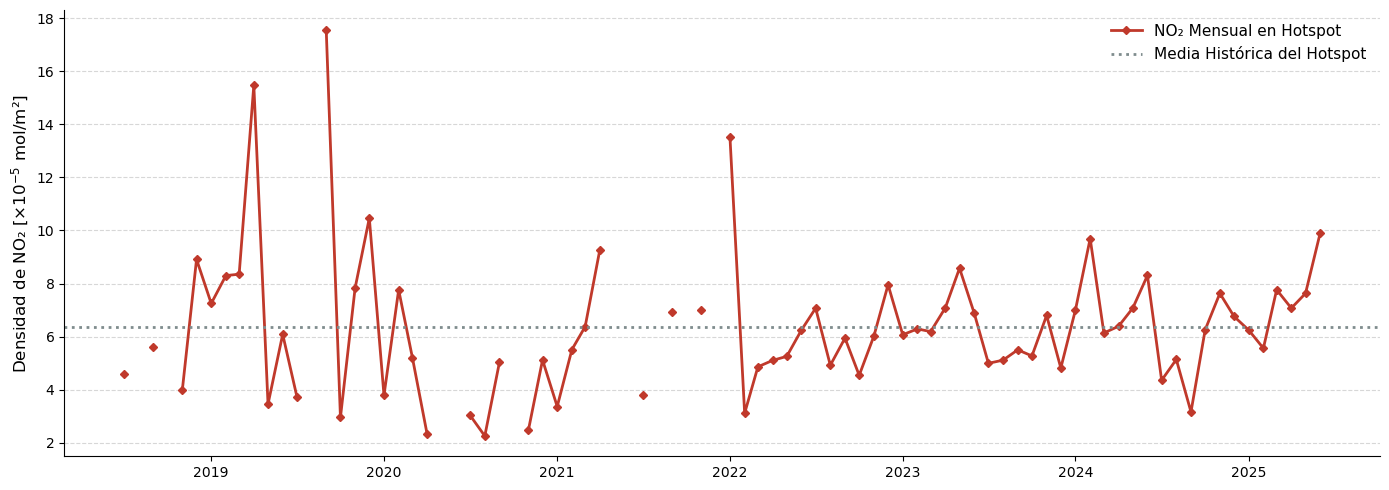

In [16]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

latitud_no2 = 14.50644994392857
longitud_no2 = -90.624926285
valor_historico_no2 = 6.354493962135166e-05

hotspot_ts = cubo_no2.sel(x=longitud_no2, y=latitud_no2, method="nearest")

df_hotspot = hotspot_ts.to_dataframe(name="concentracion").reset_index()

df_hotspot['concentracion_escalada'] = df_hotspot['concentracion'] * 1e5
valor_historico_escalado = valor_historico_no2 * 1e5

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_hotspot['time'], df_hotspot['concentracion_escalada'], 
        marker='D', markersize=4, color='#C0392B', linewidth=2, 
        label='NO₂ Mensual en Hotspot')

ax.axhline(valor_historico_escalado, 
           color='#7F8C8D', 
           linestyle=':', 
           linewidth=2,
           label='Media Histórica del Hotspot')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.set_ylabel(r"Densidad de NO₂ [$\times 10^{-5}$ mol/m²]", fontsize=12)
ax.set_xlabel("")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=False, fontsize=11)

plt.tight_layout()

plt.savefig("serie_tiempo_hotspot_no2.png", dpi=300, bbox_inches='tight')

plt.show()

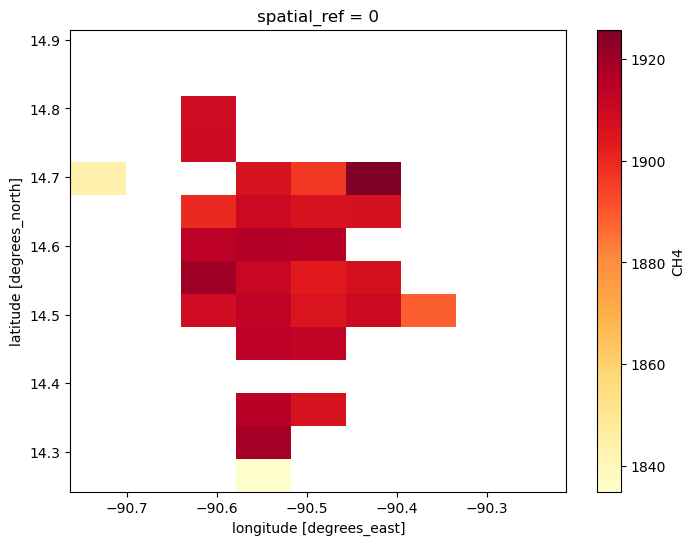

In [4]:
linea_base_ch4.plot(cmap="YlOrRd", size=6)

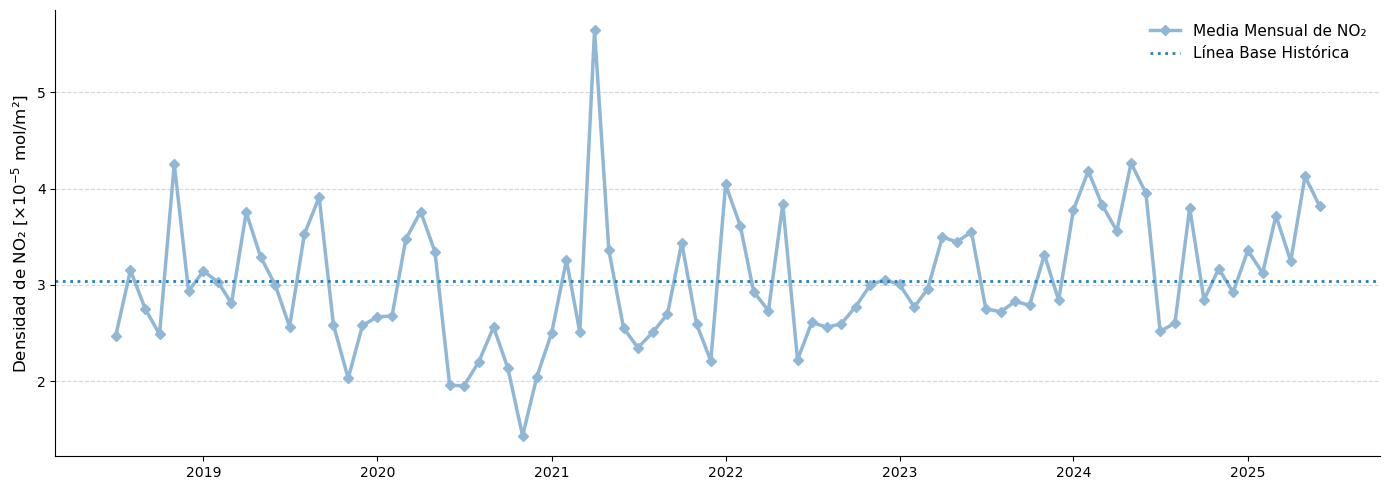

In [15]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

ts_no2 = cubo_no2.mean(dim=['x', 'y'])
df_no2 = ts_no2.to_dataframe(name="concentracion").reset_index()

df_no2['concentracion_escalada'] = df_no2['concentracion'] * 1e5

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(df_no2['time'], df_no2['concentracion_escalada'], 
        marker='D', markersize=5, color='#90B7D6', linewidth=2.5, 
        label='Media Mensual de NO₂')

media_historica = df_no2['concentracion_escalada'].mean()
ax.axhline(media_historica, 
           color='#2980B9', 
           linestyle=':', 
           linewidth=2,
           label='Línea Base Histórica')

ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))

ax.set_ylabel(r"Densidad de NO₂ [$\times 10^{-5}$ mol/m²]", fontsize=12)
ax.set_xlabel("")

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.legend(loc='upper right', frameon=False, fontsize=11)

plt.tight_layout()
plt.savefig("serie_tiempo_NO2.png", dpi=300, bbox_inches='tight')
plt.show()

In [8]:
media_linea_base_no2 = linea_base_no2.mean(skipna=True)

valor_medio_no2 = media_linea_base_no2.item()

print(f"Valor Promedio : {valor_medio_no2} mol/m²")

Valor Promedio : 3.0163011615513824e-05 mol/m²


/tmp/ipykernel_121/1246119324.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_no2, x='Mes', y='concentracion_escalada', palette="YlOrRd")


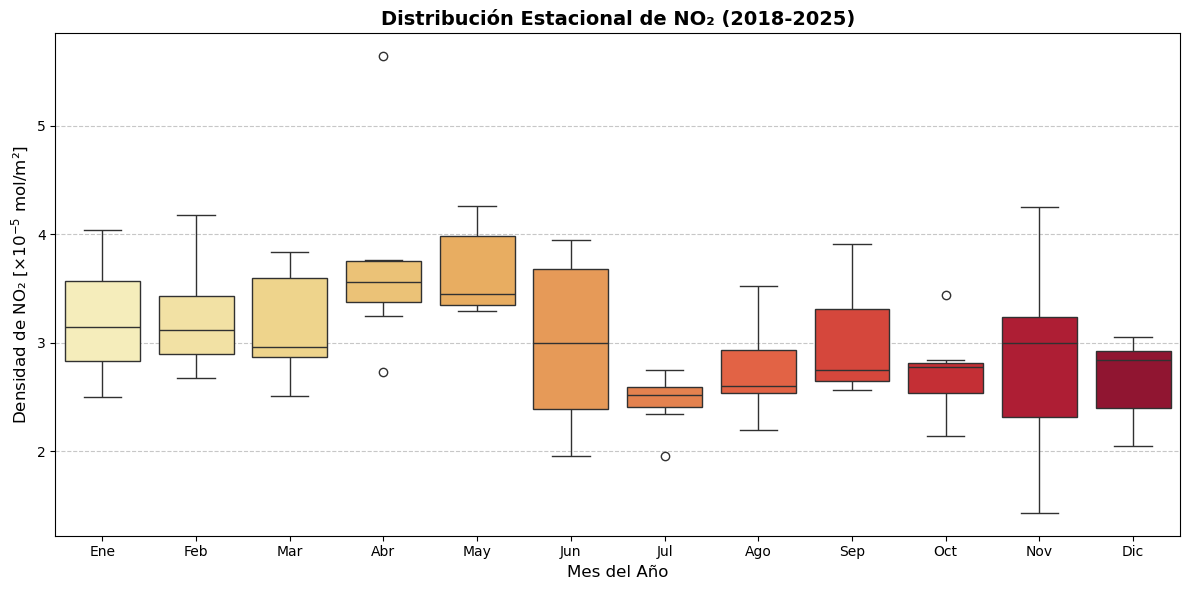

In [10]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

ts_no2 = cubo_no2.mean(dim=['x', 'y'])

df_no2 = ts_no2.to_dataframe(name="concentracion").reset_index()

df_no2['Mes_Num'] = df_no2['time'].dt.month

meses = {1:'Ene', 2:'Feb', 3:'Mar', 4:'Abr', 5:'May', 6:'Jun', 
         7:'Jul', 8:'Ago', 9:'Sep', 10:'Oct', 11:'Nov', 12:'Dic'}

df_no2['Mes'] = df_no2['Mes_Num'].map(meses)
df_no2['Mes'] = pd.Categorical(df_no2['Mes'], categories=['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic'], ordered=True)
df_no2['concentracion_escalada'] = df_no2['concentracion'] * 1e5


plt.figure(figsize=(12, 6))

sns.boxplot(data=df_no2, x='Mes', y='concentracion_escalada', palette="YlOrRd")

plt.ylabel(r"Densidad de NO₂ [$\times 10^{-5}$ mol/m²]", fontsize=12)
plt.xlabel("Mes del Año", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.savefig("distribucion_estacional_no2.png", dpi=300, bbox_inches='tight')

plt.show()

In [11]:
##verificar outliers
lista_outliers = []

for mes in df_no2['Mes_Num'].unique():
    datos_mes = df_no2[df_no2['Mes_Num'] == mes]
    
    Q1 = datos_mes['concentracion_escalada'].quantile(0.25)
    Q3 = datos_mes['concentracion_escalada'].quantile(0.75)
    IQR = Q3 - Q1
    
    limite_inferior = Q1 - 1.5 * IQR
    limite_superior = Q3 + 1.5 * IQR
    
    outliers = datos_mes[(datos_mes['concentracion_escalada'] < limite_inferior) | 
                         (datos_mes['concentracion_escalada'] > limite_superior)].copy()
    
    lista_outliers.append(outliers)

df_outliers = pd.concat(lista_outliers)

df_outliers['Año'] = df_outliers['time'].dt.year

df_outliers['Tipo_Anomalia'] = df_outliers.apply(
    lambda row: 'Pico Atípico (Alta)' if row['concentracion_escalada'] > row['concentracion_escalada'] else 'Caída Atípica (Baja)', axis=1
)
df_outliers['Tipo'] = ['Anomalía Positiva (Pico)' if val > Q3 else 'Anomalía Negativa (Caída)' for val, Q3 in zip(df_outliers['concentracion_escalada'], df_outliers['Mes_Num'].map(df_no2.groupby('Mes_Num')['concentracion_escalada'].quantile(0.75)))]

columnas_finales = ['Mes', 'Año', 'Tipo', 'concentracion_escalada']
print("Outliers detectados")
print(df_outliers[columnas_finales].sort_values(by=['Año', 'Mes']).to_string(index=False))

Outliers detectados
Mes  Año                      Tipo  concentracion_escalada
Jul 2020 Anomalía Negativa (Caída)                1.952794
Abr 2021  Anomalía Positiva (Pico)                5.642976
Oct 2021  Anomalía Positiva (Pico)                3.438919
Abr 2022 Anomalía Negativa (Caída)                2.733223


In [11]:
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import imageio.v2 as imageio
import os

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs("EPSG:4326")
cubo_no2 = xr.open_dataset("mystorage/Cubo_NO2_Final.nc")["NO2"]
output_dir = "temp_frames"
os.makedirs(output_dir, exist_ok=True)

cubo_escalado = cubo_no2 * 1e5
cubo_suavizado = cubo_escalado.rolling(time=3, center=True, min_periods=1).mean()
vmax = cubo_suavizado.max().item()
vmin = 0

filenames = []


print("Instanciando")

for i in range(len(cubo_suavizado.time)):
    mes_actual = cubo_suavizado.isel(time=i)
    fecha_str = str(mes_actual.time.values)[:7] 
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    im = mes_actual.plot.imshow(
        ax=ax, 
        cmap="turbo",
        vmin=vmin, 
        vmax=vmax, 
        add_colorbar=False,
        alpha=0.85
    )
    
    poligono_amg.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1)
    ax.set_title(f"{fecha_str}", fontsize=16, fontweight='bold', pad=20)
    ax.set_axis_off() 
    
    cbar = fig.colorbar(im, ax=ax, orientation='horizontal', pad=0.05, aspect=40)
    cbar.set_label(r"Densidad de NO₂ [$10^{-5}$ mol/m²]", fontsize=12)
    
    filename = f"{output_dir}/frame_{i:03d}.png"
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.close()
    
    filenames.append(filename)

print("Iniciando...")

gif_filename = "Animacion_NO2_AMG.gif"
with imageio.get_writer(gif_filename, mode='I', duration=3.5) as writer:
    for filename in filenames:
        image = imageio.imread(filename)
        writer.append_data(image)

for filename in set(filenames):
    os.remove(filename)
os.rmdir(output_dir)

print(f"Fin, guardado como '{gif_filename}'")

##para video:
fps_deseado = 8 
mp4_filename = "Animacion_NO2_AMG.mp4"

with imageio.get_writer(mp4_filename, format='FFMPEG', fps=fps_deseado, macro_block_size=2) as writer:
    for filename in filenames:
        image = imageio.imread(filename)
        writer.append_data(image)

for filename in set(filenames):
    os.remove(filename)
os.rmdir(output_dir)

Instanciando


IMAGEIO FFMPEG_WRITER WARNING: input image is not divisible by macro_block_size=2, resizing from (1199, 986) to (1200, 986) to ensure video compatibility with most codecs and players. To prevent resizing, make your input image divisible by the macro_block_size or set the macro_block_size to 1 (risking incompatibility).


Iniciando...
Video guardado como 'Animacion_NO2_AMG.mp4'!


Calculando la media para cada municipio
Omitiendo Lago De Amatitlan debido a problemas con la topología: No data found in bounds. Data variable: NO2
Omitiendo San Pedro Sacatepéquez debido a problemas con la topología: No data found in bounds. Data variable: NO2


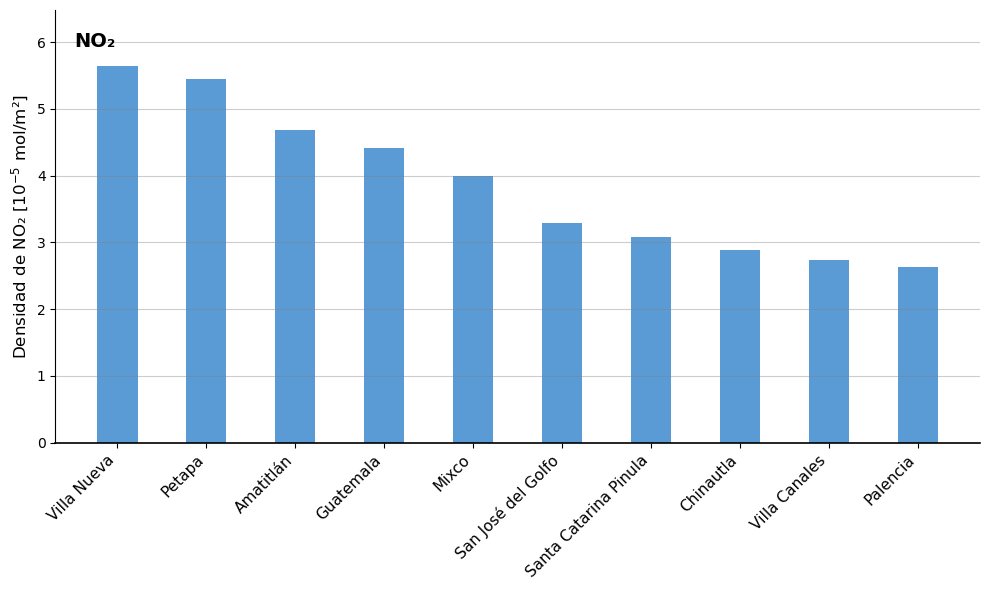


Ranking (top 10) de valores promedio de NO₂ ---
            Municipio  NO2_escalado
          Villa Nueva      5.634916
               Petapa      5.446725
            Amatitlán      4.686072
            Guatemala      4.416347
                Mixco      3.994807
   San José del Golfo      3.295857
Santa Catarina Pinula      3.083608
            Chinautla      2.886765
        Villa Canales      2.731677
             Palencia      2.627105


In [13]:
import pandas as pd

municipios_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs("EPSG:4326")

resultados = []
print("Calculando la media para cada municipio")

for index, row in municipios_amg.iterrows():
    nombre_municipio = row['adm2_name'] 
    geometria = [row['geometry']]
    
    try:
        recorte_municipal = linea_base_no2.rio.clip(geometria, municipios_amg.crs, drop=True)
        
        media_municipal = recorte_municipal.mean(skipna=True).item()
        
        resultados.append({'Municipio': nombre_municipio, 'NO2': media_municipal})
    except Exception as e:
        print(f"Omitiendo {nombre_municipio} debido a problemas con la topología: {e}")

df_ranking = pd.DataFrame(resultados)
df_ranking['NO2_escalado'] = df_ranking['NO2'] * 1e5
df_ranking = df_ranking.sort_values(by='NO2_escalado', ascending=False).head(10)

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(df_ranking['Municipio'], df_ranking['NO2_escalado'], color='#5B9BD5', width=0.45)

ax.text(0.02, 0.95, "NO₂", transform=ax.transAxes, fontsize=14, fontweight='bold', va='top')

ax.set_ylabel(r"Densidad de NO₂ [$10^{-5}$ mol/m²]", fontsize=12)
ax.set_ylim(0, df_ranking['NO2_escalado'].max() * 1.15)

plt.xticks(rotation=45, ha='right', fontsize=11)
ax.set_xlabel("")

ax.grid(axis='y', linestyle='-', alpha=0.4, color='gray')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_linewidth(1.2) 

plt.tight_layout()

plt.savefig("Top10_Municipios_NO2.png", dpi=300, bbox_inches='tight')

plt.show()

print("\nRanking (top 10) de valores promedio de NO₂ ---")
print(df_ranking[['Municipio', 'NO2_escalado']].to_string(index=False))

Dividiendo el buffer de la CA-9 en Barlovento y Sotavento...

--- IMPACTO MICRO-ESPACIAL POR EFECTO DE ARRASTRE ---
Llegada del viento (Barlovento / Lado Este) : 6.06 x 10^-5 mol/m²
Acumulación vehicular (Sotavento / Lado Oeste) : 6.24 x 10^-5 mol/m²
Aumento de contaminación a favor del viento : +3.0%



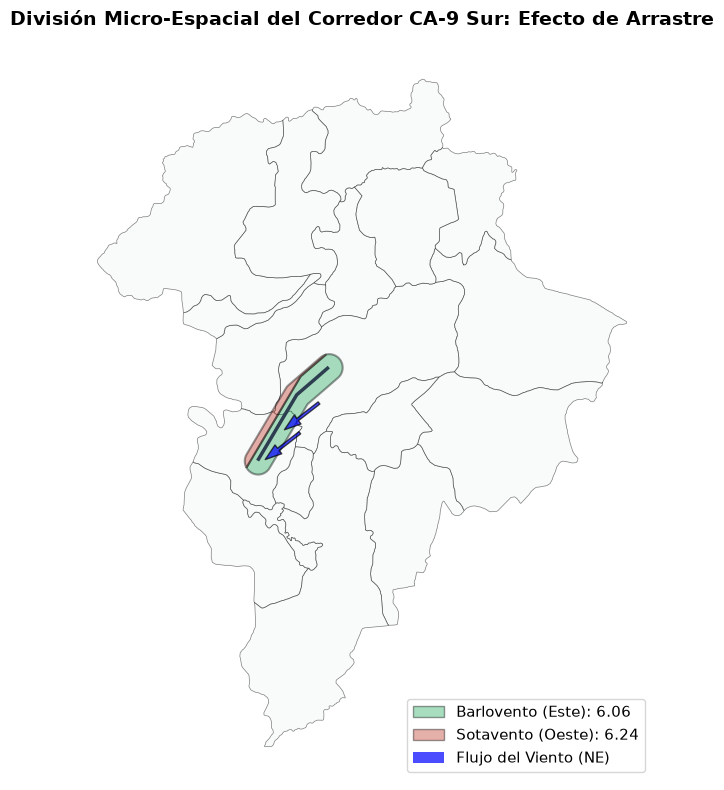

In [10]:
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import LineString
from shapely.affinity import scale
from shapely.ops import split
municipios_amg = gpd.read_file("amg_limites.geojson").to_crs("EPSG:4326")

print("Dividiendo el buffer de la CA-9 en Barlovento y Sotavento...")

coordenadas_corredor = [
    (-90.521811, 14.624648),
    (-90.535576, 14.613063), 
    (-90.555191, 14.596728), 
    (-90.595889, 14.530440)
]
linea_ca9 = LineString(coordenadas_corredor)
gdf_linea = gpd.GeoDataFrame(index=[0], geometry=[linea_ca9], crs="EPSG:4326")

buffer_utm = gdf_linea.to_crs("EPSG:32615").buffer(1500)
gdf_buffer = gpd.GeoDataFrame(geometry=buffer_utm, crs="EPSG:32615").to_crs("EPSG:4326")
poligono_buffer = gdf_buffer.geometry.iloc[0]

linea_extendida = scale(linea_ca9, xfact=2.0, yfact=2.0)
mitades = split(poligono_buffer, linea_extendida)

poligono_este = None
poligono_oeste = None

for poly in mitades.geoms:
    if poligono_este is None:
        poligono_este = poly
        poligono_oeste = poly
    else:
        if poly.bounds[0] > poligono_oeste.bounds[0]:
            poligono_este = poly
        else:
            poligono_oeste = poly

gdf_barlovento = gpd.GeoDataFrame(index=[0], geometry=[poligono_este], crs="EPSG:4326")
gdf_sotavento = gpd.GeoDataFrame(index=[0], geometry=[poligono_oeste], crs="EPSG:4326")

recorte_barlovento = linea_base_no2.rio.clip(gdf_barlovento.geometry, gdf_barlovento.crs, drop=True)
recorte_sotavento = linea_base_no2.rio.clip(gdf_sotavento.geometry, gdf_sotavento.crs, drop=True)

media_barlovento = recorte_barlovento.mean(skipna=True).item() * 1e5
media_sotavento = recorte_sotavento.mean(skipna=True).item() * 1e5
diferencia_arrastre = ((media_sotavento / media_barlovento) - 1) * 100

print(f"Llegada del viento (Barlovento / Lado Este) : {media_barlovento:.2f} x 10^-5 mol/m²")
print(f"Acumulación vehicular (Sotavento / Lado Oeste) : {media_sotavento:.2f} x 10^-5 mol/m²")
print(f"Aumento de contaminación a favor del viento : +{diferencia_arrastre:.1f}%\n")

fig, ax = plt.subplots(figsize=(10, 8))

municipios_amg.plot(ax=ax, facecolor="#F4F6F6", edgecolor="black", linewidth=0.5, alpha=0.5)

gdf_barlovento.plot(ax=ax, facecolor="#27AE60", edgecolor="black", linewidth=1.5, alpha=0.4, label="Barlovento (Viento limpio)")
gdf_sotavento.plot(ax=ax, facecolor="#C0392B", edgecolor="black", linewidth=1.5, alpha=0.4, label="Sotavento (Arrastre tóxico)")

gdf_linea.plot(ax=ax, color="#2C3E50", linewidth=2.5)

ax.annotate('', xy=(-90.57, 14.56), xytext=(-90.53, 14.59),
            arrowprops=dict(facecolor='blue', shrink=0.05, width=2, headwidth=8, alpha=0.7))
ax.annotate('', xy=(-90.59, 14.53), xytext=(-90.55, 14.56),
            arrowprops=dict(facecolor='blue', shrink=0.05, width=2, headwidth=8, alpha=0.7))

ax.set_title("División Micro-Espacial del Corredor CA-9 Sur: Efecto de Arrastre", fontsize=14, fontweight='bold', pad=15)
ax.set_axis_off()

import matplotlib.patches as mpatches
leyenda_barlo = mpatches.Patch(facecolor='#27AE60', alpha=0.4, edgecolor='black', label=f'Barlovento (Este): {media_barlovento:.2f}')
leyenda_sota = mpatches.Patch(facecolor='#C0392B', alpha=0.4, edgecolor='black', label=f'Sotavento (Oeste): {media_sotavento:.2f}')
leyenda_viento = mpatches.Patch(facecolor='blue', alpha=0.7, label='Flujo del Viento (NE)')
ax.legend(handles=[leyenda_barlo, leyenda_sota, leyenda_viento], loc='lower right', frameon=True, fontsize=11)

plt.tight_layout()
plt.show()

In [12]:
import numpy as np

base_auditoria = linea_base_no2.squeeze(drop=True).copy()

if base_auditoria.ndim != 2:
    raise ValueError("La línea base debe tener únicamente dos dimensiones espaciales.")

if base_auditoria.rio.crs is None:
    raise ValueError("La línea base no tiene un CRS definido.")

nodata = base_auditoria.rio.nodata
if nodata is not None and np.isfinite(nodata):
    base_auditoria = base_auditoria.where(base_auditoria != nodata)

base_auditoria = base_auditoria.where(
    np.isfinite(base_auditoria)
).rio.write_nodata(np.nan)


barlo_utm = gdf_barlovento.to_crs("EPSG:32615").geometry.iloc[0]
sota_utm = gdf_sotavento.to_crs("EPSG:32615").geometry.iloc[0]
buffer_auditoria_utm = gdf_buffer.to_crs("EPSG:32615").geometry.iloc[0]

union_flancos = barlo_utm.union(sota_utm)

print(f"¿Los dos polígonos son iguales?: {barlo_utm.equals(sota_utm)}")
print(
    "Superficie compartida entre polígonos: "
    f"{barlo_utm.intersection(sota_utm).area:.6f} m²"
)
print(
    "Superficie del buffer sin asignar: "
    f"{buffer_auditoria_utm.difference(union_flancos).area:.6f} m²"
)


def recortar_para_auditoria(gdf):
    return base_auditoria.rio.clip(
        gdf.geometry,
        gdf.crs,
        drop=False,
        all_touched=False
    )

aud_barlo = recortar_para_auditoria(gdf_barlovento)
aud_sota = recortar_para_auditoria(gdf_sotavento)
aud_buffer = recortar_para_auditoria(gdf_buffer)

validas_barlo = np.isfinite(aud_barlo)
validas_sota = np.isfinite(aud_sota)
validas_buffer = np.isfinite(aud_buffer)

compartidas = validas_barlo & validas_sota
union_celdas = validas_barlo | validas_sota
sin_asignar = validas_buffer & ~union_celdas
fuera_buffer = union_celdas & ~validas_buffer

def contar(mascara):
    return int(mascara.sum().item())

print("\nCeldas válidas")
print(f"Buffer completo: {contar(validas_buffer)}")
print(f"Barlovento: {contar(validas_barlo)}")
print(f"Sotavento: {contar(validas_sota)}")
print(f"Compartidas entre flancos: {contar(compartidas)}")
print(f"Dentro del buffer, sin asignar: {contar(sin_asignar)}")
print(f"Asignadas a flancos, fuera del buffer: {contar(fuera_buffer)}")

print("\nMedias producidas")
print(f"Barlovento: {aud_barlo.mean(skipna=True).item() * 1e5:.4f} × 10⁻⁵ mol/m²")
print(f"Sotavento: {aud_sota.mean(skipna=True).item() * 1e5:.4f} × 10⁻⁵ mol/m²")

if contar(compartidas) > 0:
    print("\nEstas celdas están participando en AMBAS medias:")
    tabla_compartidas = (
        base_auditoria.where(compartidas)
        .to_dataframe(name="NO2_mol_m2")
        .dropna(subset=["NO2_mol_m2"])
    )
    print(tabla_compartidas[["NO2_mol_m2"]].to_string())
else:
    print("\nNo se duplican celdas válidas entre los dos flancos.")

AUDITORÍA GEOMÉTRICA
¿Los dos polígonos son iguales?: False
Superficie compartida entre polígonos: 0.000000 m²
Superficie del buffer sin asignar: 0.007823 m²

Celdas válidas
Buffer completo: 3
Barlovento: 1
Sotavento: 2
Compartidas entre flancos: 0
Dentro del buffer, sin asignar: 0
Asignadas a flancos, fuera del buffer: 0

Medias producidas
Barlovento: 6.0552 × 10⁻⁵ mol/m²
Sotavento: 6.2358 × 10⁻⁵ mol/m²

No se duplican celdas válidas entre los dos flancos.


In [5]:
import pymannkendall as mk

df = pd.read_csv('serie_maestra_no2_amg.csv')

resultado_amg = mk.original_test(df['no2_amg'])

print("Prueba Mann-Kendall")
print(f"Tendencia detectada (trend): {resultado_amg.trend}")
print(f"P-value (Significancia): {resultado_amg.p} ")
print(f"Z-score: {resultado_amg.z}")
print(f"Pendiente de Sen (Slope): {resultado_amg.slope}")

resultado_hotspot = mk.original_test(df['no2_hotspot'])

print("Prueba Mann-Kendall para Hotspot")
print(f"Tendencia detectada (trend): {resultado_hotspot.trend}")
print(f"P-value (Significancia): {resultado_hotspot.p}")
print(f"Z-score: {resultado_hotspot.z}")
print(f"Pendiente de Sen (Slope): {resultado_hotspot.slope}")

Prueba Mann-Kendall
Tendencia detectada (trend): increasing
P-value (Significancia): 0.0023638213687553478 
Z-score: 3.0402496288392142
Pendiente de Sen (Slope): 8.068597648083618e-08
Prueba Mann-Kendall para Hotspot
Tendencia detectada (trend): no trend
P-value (Significancia): 0.11062665817460515
Z-score: 1.5953828077249206
Pendiente de Sen (Slope): 1.8861247126436778e-07


In [ ]:
import xarray as xr
import geopandas as gpd
import matplotlib.pyplot as plt
import imageio.v2 as imageio
import os

poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs("EPSG:4326")
cubo_no2 = xr.open_dataset("mystorage/Cubo_NO2_Final.nc")["NO2"]
output_dir = "temp_frames"
os.makedirs(output_dir, exist_ok=True)

cubo_escalado = cubo_no2 * 1e5
cubo_suavizado = cubo_escalado.rolling(time=3, center=True, min_periods=1).mean()
vmax = cubo_suavizado.max().item()
vmin = 0

filenames = []


print("Instanciando")

for i in range(len(cubo_suavizado.time)):
    mes_actual = cubo_suavizado.isel(time=i)
    fecha_str = str(mes_actual.time.values)[:7] 
    
    fig, ax = plt.subplots(figsize=(10, 8))
    
    im = mes_actual.plot.imshow(
        ax=ax, 
        cmap="turbo",
        vmin=vmin, 
        vmax=vmax, 
        add_colorbar=False,
        alpha=0.85
    )
    
    poligono_amg.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=1)
    ax.set_title(f"{fecha_str}", fontsize=16, fontweight='bold', pad=20)
    ax.set_axis_off() 
    
    cbar = fig.colorbar(im, ax=ax, orientation='horizontal', pad=0.05, aspect=40)
    cbar.set_label(r"Densidad de NO₂ [$10^{-5}$ mol/m²]", fontsize=12)
    
    filename = f"{output_dir}/frame_{i:03d}.png"
    plt.savefig(filename, dpi=150, bbox_inches='tight')
    plt.close()
    
    filenames.append(filename)

print("Iniciando...")

##para video:
fps_deseado = 3
mp4_filename = "Animacion_NO2_AMG3.mp4"

with imageio.get_writer(mp4_filename, format='FFMPEG', fps=fps_deseado, macro_block_size=2) as writer:
    for filename in filenames:
        image = imageio.imread(filename)
        writer.append_data(image)

for filename in set(filenames):
    os.remove(filename)
os.rmdir(output_dir)

In [ ]:
import geopandas as gpd
from shapely.geometry import LineString

coordenadas_corredor = [
    (-90.521811, 14.624648),
    (-90.535576, 14.613063),
    (-90.555191, 14.596728),
    (-90.595889, 14.530440) 
]

linea_ca9 = LineString(coordenadas_corredor)
gdf_linea = gpd.GeoDataFrame(index=[0], geometry=[linea_ca9], crs="EPSG:4326")

gdf_linea_utm = gdf_linea.to_crs("EPSG:32615")

gdf_buffer_utm = gdf_linea_utm.buffer(1500)

gdf_buffer = gpd.GeoDataFrame(geometry=gdf_buffer_utm, crs="EPSG:32615").to_crs("EPSG:4326")

recorte_corredor = linea_base_no2.rio.clip(gdf_buffer.geometry, gdf_buffer.crs, drop=True)
media_corredor = recorte_corredor.mean(skipna=True).item()

media_global_amg = linea_base_no2.mean(skipna=True).item()

media_corredor_esc = media_corredor * 1e5
media_global_esc = media_global_amg * 1e5

diferencia_porcentual = ((media_corredor_esc / media_global_esc) - 1) * 100

print(f"Concentración media en la autopista (Buffer 1.5km) : {media_corredor_esc:.2f} x 10^-5 mol/m²")
print(f"Concentración media del Área Metropolitana         : {media_global_esc:.2f} x 10^-5 mol/m²")
print(f"Impacto directo de la infraestructura              : +{diferencia_porcentual:.1f}% de contaminación sobre la media urbana")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.lines as mlines
fig, ax = plt.subplots(figsize=(10, 8))

im = linea_base_no2.plot.imshow(
    ax=ax, 
    cmap="Spectral_r", 
    cbar_kwargs={'label': 'Densidad de Columna Vertical de NO₂ [mol/m²]'}

)
poligono_amg = gpd.read_file("mystorage/amg_limites.geojson").to_crs("EPSG:4326")
poligono_amg.plot(ax=ax, facecolor="none", edgecolor="black", linewidth=0.8, alpha=0.7)

gdf_buffer.plot(ax=ax, facecolor="none", edgecolor="#2980B9", linewidth=2, linestyle='--', label="Buffer 1.5 km")

gdf_linea.plot(ax=ax, color="#2C3E50", linewidth=2, label="Corredor Vial CA-9")

ax.set_xticks([])
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.set_axis_off()
for spine in ax.spines.values():
    spine.set_visible(False)
ax.set_title("Ruta Vehicular", fontsize=14, fontweight='bold', pad=15)
ax.set_axis_off()
linea_leyenda = mlines.Line2D([], [], color='#2C3E50', linewidth=2, label='Ruta Vehicular')
buffer_leyenda = mpatches.Patch(edgecolor='#2980B9', facecolor='none', linestyle='--', linewidth=2, label='Área de Influencia (1.5 km)')
ax.legend(handles=[linea_leyenda, buffer_leyenda], loc='upper left', frameon=True)

plt.tight_layout()
plt.show()
